# 06 · Complete evaluation (Phase 8, E6)

Standard checks every ML project needs, on the **same speaker-independent folds and settings** as Phase 6:
1. **Classification report:** precision, recall, F1 and support per emotion
2. **ROC-AUC** (one-vs-rest) and ROC curves
3. **Calibration:** when the model says "80% sure", is it right 80% of the time?
4. **Overfitting check:** training vs validation UAR for every model
5. **Learning curve:** does performance keep improving with more training speakers?

In [1]:
import sys, json
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, balanced_accuracy_score
from src.models import load_corpus, CLASSES, DEFAULT_LAYER
from src.evaluation import refit_folds, expected_calibration_error, learning_curve_speakers
from src.experiments import FIXED_C

OUT = PROJECT_ROOT / "results" / "phase8"; OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "results" / "figures"
NAME = {"ravdess": "RAVDESS", "cremad": "CREMA-D"}
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"
INK, MUTED, GREY = "#0b0b0b", "#52514e", "#b8b6ad"
EMO_COLOUR = dict(zip(CLASSES, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET]))
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.edgecolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "figure.dpi": 110})
data = {c: load_corpus(c) for c in ["ravdess", "cremad"]}
summary = {}

## Refit the Phase 6 models (same folds, same hyperparameters) to get probabilities and training scores

In [2]:
CONFIGS = [(fs, "logreg") for fs in ["egemaps", "wavlm", "fusion"]] + \
          [("egemaps", m) for m in ["svm", "lgbm", "mlp"]] + [("wavlm", "mlp")]
res = {}
for c in data:
    for fs, m in CONFIGS:
        res[(c, fs, m)] = refit_folds(data[c], c, fs, m)
        f = res[(c, fs, m)]["folds"]
        print(f"{c:8s} {fs:8s} {m:7s} train UAR {f.train_uar.mean():.3f} | validation UAR {f.val_uar.mean():.3f}")

ravdess  egemaps  logreg  train UAR 0.730 | validation UAR 0.554
ravdess  wavlm    logreg  train UAR 0.997 | validation UAR 0.810
ravdess  fusion   logreg  train UAR 0.997 | validation UAR 0.822
ravdess  egemaps  svm     train UAR 0.861 | validation UAR 0.524
ravdess  egemaps  lgbm    train UAR 1.000 | validation UAR 0.539
ravdess  egemaps  mlp     train UAR 0.760 | validation UAR 0.514
ravdess  wavlm    mlp     train UAR 0.986 | validation UAR 0.786
cremad   egemaps  logreg  train UAR 0.559 | validation UAR 0.515
cremad   wavlm    logreg  train UAR 0.854 | validation UAR 0.738
cremad   fusion   logreg  train UAR 0.866 | validation UAR 0.741
cremad   egemaps  svm     train UAR 0.655 | validation UAR 0.528
cremad   egemaps  lgbm    train UAR 0.977 | validation UAR 0.538
cremad   egemaps  mlp     train UAR 0.662 | validation UAR 0.520
cremad   wavlm    mlp     train UAR 0.957 | validation UAR 0.725


## 1. Classification reports (best model: LogReg + fusion; interpretable model: LogReg + eGeMAPS)

In [3]:
reports = {}
for c in data:
    y = data[c]["y"]
    for fs in ["fusion", "egemaps"]:
        pred = res[(c, fs, "logreg")]["proba"].argmax(1)
        rep = classification_report(y, pred, target_names=CLASSES, digits=3, output_dict=True)
        reports[f"{c}_{fs}"] = rep
        print(f"===== {NAME[c]} · LogReg + {fs} =====")
        print(classification_report(y, pred, target_names=CLASSES, digits=3))
        pd.DataFrame(rep).T.round(3).to_csv(OUT / f"e6_report_{c}_{fs}_logreg.csv")
summary["classification_reports"] = {k: {cls: {m: round(v, 3) for m, v in d.items()} if isinstance(d, dict) else round(d, 3)
                                         for cls, d in r.items()} for k, r in reports.items()}

===== RAVDESS · LogReg + fusion =====
              precision    recall  f1-score   support

     neutral      0.755     0.865     0.806        96
       happy      0.844     0.760     0.800       192
         sad      0.681     0.745     0.711       192
       angry      0.891     0.896     0.894       192
     fearful      0.825     0.786     0.805       192
     disgust      0.904     0.880     0.892       192

    accuracy                          0.818      1056
   macro avg      0.817     0.822     0.818      1056
weighted avg      0.822     0.818     0.819      1056

===== RAVDESS · LogReg + egemaps =====
              precision    recall  f1-score   support

     neutral      0.391     0.688     0.498        96
       happy      0.474     0.422     0.446       192
         sad      0.524     0.505     0.515       192
       angry      0.636     0.656     0.646       192
     fearful      0.576     0.474     0.520       192
     disgust      0.634     0.578     0.605       192



## 2. ROC-AUC (one-vs-rest)
0.5 = random, 1.0 = perfect ranking. AUC measures how well the model *ranks* clips, independently of the decision threshold.

In [4]:
auc = []
for c in data:
    y = data[c]["y"]
    for fs, m in CONFIGS:
        p = res[(c, fs, m)]["proba"]
        if np.isnan(p).any():
            continue   # SVM has no probabilities
        auc.append({"corpus": NAME[c], "features": fs, "model": m,
                    "macro_auc": roc_auc_score(y, p, multi_class="ovr", average="macro"),
                    **{f"auc_{e}": roc_auc_score((y == k).astype(int), p[:, k]) for k, e in enumerate(CLASSES)}})
auc = pd.DataFrame(auc); auc.to_csv(OUT / "e6_roc_auc.csv", index=False)
summary["roc_auc"] = auc.round(3).to_dict(orient="records")
auc.round(3)

,corpus,features,model,macro_auc,auc_neutral,auc_happy,auc_sad,auc_angry,auc_fearful,auc_disgust
0,RAVDESS,egemaps,logreg,0.853,0.914,0.792,0.836,0.886,0.835,0.857
1,RAVDESS,wavlm,logreg,0.969,0.989,0.968,0.925,0.986,0.962,0.985
2,RAVDESS,fusion,logreg,0.968,0.989,0.966,0.923,0.984,0.959,0.988
3,RAVDESS,egemaps,lgbm,0.853,0.903,0.800,0.840,0.887,0.830,0.859
4,RAVDESS,egemaps,mlp,0.853,0.888,0.806,0.847,0.880,0.833,0.863
5,RAVDESS,wavlm,mlp,0.966,0.984,0.958,0.934,0.979,0.960,0.980
6,CREMA-D,egemaps,logreg,0.833,0.867,0.820,0.859,0.916,0.783,0.754
7,CREMA-D,wavlm,logreg,0.943,0.979,0.952,0.916,0.970,0.914,0.929
8,CREMA-D,fusion,logreg,0.944,0.980,0.953,0.915,0.969,0.915,0.929
9,CREMA-D,egemaps,lgbm,0.844,0.877,0.832,0.867,0.914,0.797,0.775


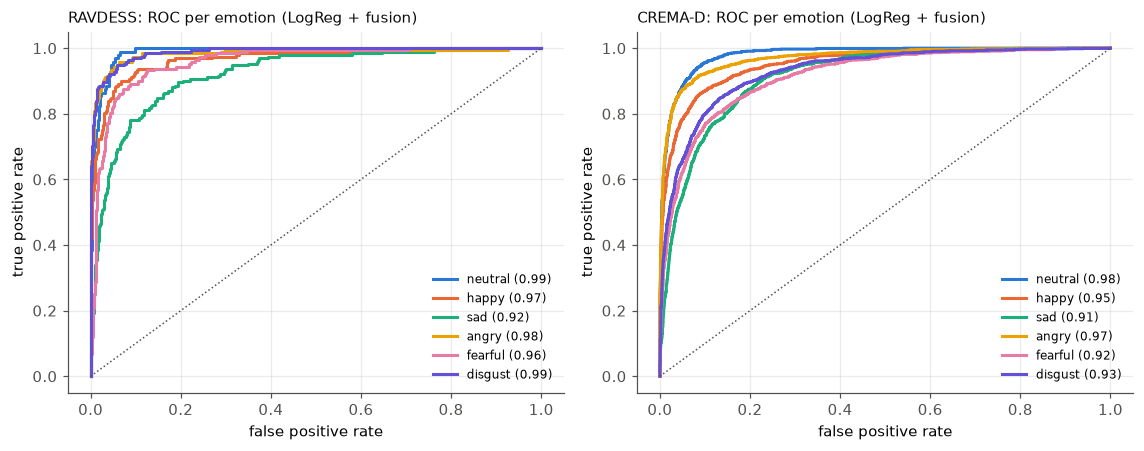

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, c in zip(axes, data):
    y, p = data[c]["y"], res[(c, "fusion", "logreg")]["proba"]
    for k, e in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve((y == k).astype(int), p[:, k])
        ax.plot(fpr, tpr, lw=2, color=EMO_COLOUR[e], label=f"{e} ({roc_auc_score((y == k).astype(int), p[:, k]):.2f})")
    ax.plot([0, 1], [0, 1], ls=":", color=MUTED, lw=1)
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.set_title(f"{NAME[c]}: ROC per emotion (LogReg + fusion)", loc="left", color=INK, fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIG_DIR / "p8_e6_roc.png", bbox_inches="tight"); plt.show()

## 3. Calibration: can we trust the model's confidence?
**ECE** (expected calibration error) = average gap between confidence and actual accuracy. 0 = perfectly honest confidence.

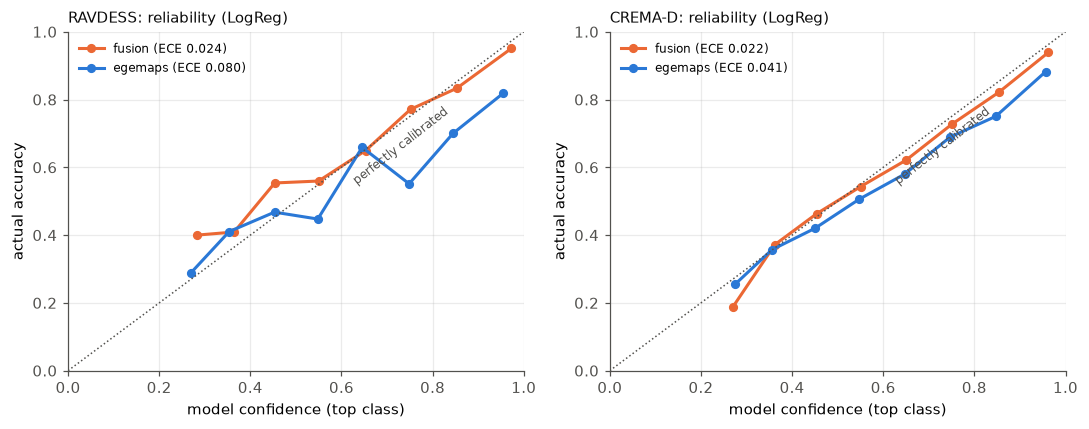

{'ravdess_fusion': 0.0245, 'ravdess_egemaps': 0.0795, 'cremad_fusion': 0.0218, 'cremad_egemaps': 0.0406}


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
cal = {}
for ax, c in zip(axes, data):
    y = data[c]["y"]
    for fs, col in [("fusion", ORANGE), ("egemaps", BLUE)]:
        ece, tab = expected_calibration_error(res[(c, fs, "logreg")]["proba"], y)
        cal[f"{c}_{fs}"] = round(ece, 4)
        ax.plot(tab["confidence"], tab["accuracy"], marker="o", ms=5, lw=2, color=col, label=f"{fs} (ECE {ece:.3f})")
    ax.plot([0, 1], [0, 1], ls=":", color=MUTED, lw=1); ax.text(0.62, 0.55, "perfectly calibrated", color=MUTED, fontsize=8, rotation=38)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("model confidence (top class)"); ax.set_ylabel("actual accuracy")
    ax.set_title(f"{NAME[c]}: reliability (LogReg)", loc="left", color=INK, fontsize=10); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "p8_e6_calibration.png", bbox_inches="tight"); plt.show()
summary["calibration_ece"] = cal; print(cal)

Points **below** the diagonal mean the model is **over-confident**; points above mean under-confident.
`class_weight="balanced"` re-weights classes during training, which can shift probabilities, so the demo app must show confidence **with this caveat**.

## 4. Overfitting check: training vs validation UAR
A large gap = the model memorises training speakers rather than learning emotion.

In [7]:
rows = []
for (c, fs, m), r in res.items():
    f = r["folds"]
    rows.append({"corpus": NAME[c], "features": fs, "model": m,
                 "train_uar": f.train_uar.mean(), "val_uar": f.val_uar.mean(),
                 "gap_pts": 100 * (f.train_uar.mean() - f.val_uar.mean())})
over = pd.DataFrame(rows); over.to_csv(OUT / "e6_overfitting.csv", index=False)
summary["overfitting"] = over.round(3).to_dict(orient="records")
(over.set_index(["corpus", "features", "model"]) * [100, 100, 1]).round(1)

train_uar  val_uar  gap_pts
corpus  features model                              
RAVDESS egemaps  logreg       73.0     55.4     17.6
        wavlm    logreg       99.7     81.0     18.6
        fusion   logreg       99.7     82.2     17.5
        egemaps  svm          86.1     52.4     33.7
                 lgbm        100.0     53.9     46.1
                 mlp          76.0     51.4     24.6
        wavlm    mlp          98.6     78.6     20.0
CREMA-D egemaps  logreg       55.9     51.5      4.5
        wavlm    logreg       85.4     73.8     11.6
        fusion   logreg       86.6     74.1     12.5
        egemaps  svm          65.5     52.8     12.7
                 lgbm         97.7     53.8     43.9
                 mlp          66.2     52.0     14.3
        wavlm    mlp          95.7     72.5     23.2

## 5. Learning curve: does more training data (more speakers) help? (CREMA-D, LogReg)

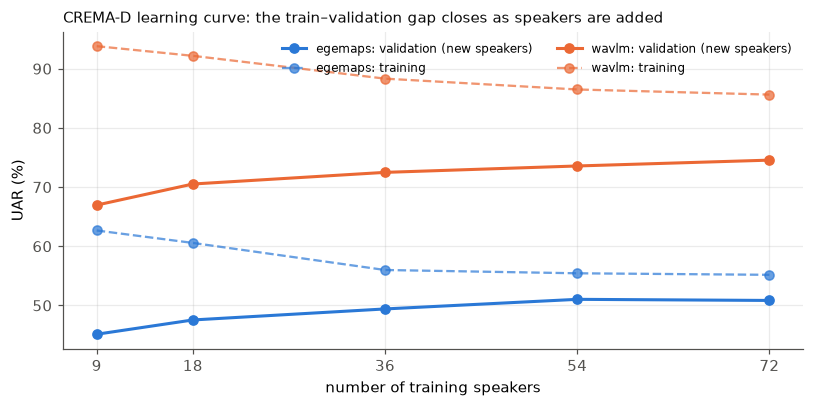

egemaps             wavlm        
           train_uar val_uar train_uar val_uar
n_speakers                                    
9               62.7    45.1      93.8    67.0
18              60.6    47.5      92.2    70.5
36              56.0    49.4      88.3    72.5
54              55.4    51.0      86.5    73.6
72              55.2    50.8      85.6    74.6

In [8]:
SIZES = [9, 18, 36, 54, 72]
lc = {fs: learning_curve_speakers(data["cremad"], fs, None if fs == "egemaps" else DEFAULT_LAYER, FIXED_C[fs], SIZES)
      for fs in ["egemaps", "wavlm"]}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for fs, col in [("egemaps", BLUE), ("wavlm", ORANGE)]:
    g = lc[fs].groupby("n_speakers").mean()
    ax.plot(g.index, g["val_uar"] * 100, marker="o", lw=2, color=col, label=f"{fs}: validation (new speakers)")
    ax.plot(g.index, g["train_uar"] * 100, marker="o", lw=1.5, ls="--", color=col, alpha=0.7, label=f"{fs}: training")
ax.set_xlabel("number of training speakers"); ax.set_ylabel("UAR (%)"); ax.set_xticks(SIZES)
ax.set_title("CREMA-D learning curve: the train–validation gap closes as speakers are added", loc="left", color=INK, fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIG_DIR / "p8_e6_learning_curve.png", bbox_inches="tight"); plt.show()
lc_tab = pd.concat({fs: lc[fs].groupby("n_speakers")[["train_uar", "val_uar"]].mean() for fs in lc}, axis=1)
summary["learning_curve"] = {fs: lc[fs].groupby("n_speakers")[["train_uar", "val_uar"]].mean().round(4).to_dict() for fs in lc}
(lc_tab * 100).round(1)

In [9]:
(PROJECT_ROOT / "results" / "phase8_e6_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("saved results/phase8_e6_summary.json")

saved results/phase8_e6_summary.json
